# Caso integrador: la base B-23

**Avanzado · Jornada 4 · Bloque 4.5 · diapositivas caso-enunciado, caso-guia, presentaciones y respuesta-modelo**

La base B-23 pierde energía desde marzo: ¿revisar los cargadores o cambiar 600 baterías? El cuaderno
guía los cinco pasos del caso (auditar, confirmar, separar, cuantificar, recomendar y vigilar) y
termina con la estructura de la nota de decisión de una página.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## El encargo

> «La base de carga **B-23** muestra un aumento de la energía no contabilizada desde marzo. Hay
> presupuesto para una **campaña de revisión de cargadores** o para **sustituir las 600 baterías de
> primera generación** que quedan en la base, no para ambas. Recomienda una opción y cómo vigilarás
> que ha funcionado.»

La **energía no contabilizada** es la que entra en la base y no llega a las baterías según sus propios
registros (`consumo_kwh − entregada_kwh`). Si sube, o se está perdiendo energía de verdad, o alguien
la está contando mal.

Equipos de 3–4 personas, 30 minutos. **Entregable:** una nota de decisión de una página, con la
conclusión primero, presentada en 3 minutos (la estructura está al final del cuaderno). La guía tiene
cinco pasos, uno por jornada del curso, más o menos:

1. **Auditar** los datos (J1).
2. **Confirmar con SPC** que el cambio es real y no la estación (J4).
3. **Separar** la pérdida real de la medición a la baja (J1 y J2).
4. **Cuantificar** con incertidumbre: un rango, no solo un número (J1).
5. **Recomendar y vigilar**: una opción y su gráfico de control.

No todo lo que os damos hace falta, y no todo lo que hace falta se ve a la primera. Como en la vida
real. Las celdas marcadas con `# COMPLETAD` o `# ←` son vuestras.

## 0. Los datos que recibe cada equipo

- `energia_bases/quince_min_b23.csv`: consumo de B-23 cada 15 minutos durante dos años (`ts_utc`,
  inicio del intervalo en UTC; `kw`, potencia media).
- `energia_bases/diario.csv`: por base y día, consumo, energía que dicen recibir las baterías de cada
  generación (`entregada_g1_kwh`, las BX-450 de primera; `entregada_g2_kwh`, las de segunda), cuántas
  baterías de cada generación tiene la base, energía no contabilizada y mínimo nocturno.
- `inventario_baterias/baterias.csv`: todas las baterías, con su modelo, generación, base, alta y baja.
- `incidencias/incidencias.csv`: incidencias del servicio.
- La telemetría de las bicis está en `telemetria/` si la queréis.

In [2]:
# Tablas con coma decimal y tres ayudas de formato en español.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha corta en español: 22-12-2025."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"

def limites_xmr(serie):
    """Media, rango móvil medio y límites naturales: media ± 2,66 × rango móvil medio."""
    media = serie.mean()
    rango_movil_medio = serie.diff().abs().mean()
    return media, rango_movil_medio, media - 2.66 * rango_movil_medio, media + 2.66 * rango_movil_medio


quince = pd.read_csv(DATOS / "energia_bases" / "quince_min_b23.csv")
quince["ts_utc"] = pd.to_datetime(quince["ts_utc"])
diario = pd.read_csv(DATOS / "energia_bases" / "diario.csv", parse_dates=["fecha"])
b23 = diario[diario["base_id"] == "B-23"].set_index("fecha")
baterias = pd.read_csv(DATOS / "inventario_baterias" / "baterias.csv")
incidencias = pd.read_csv(DATOS / "incidencias" / "incidencias.csv")
print(f"Cuartos de hora de B-23: {n(len(quince))}; días del diario: {len(b23)} "
      f"({fecha(b23.index[0])} a {fecha(b23.index[-1])})")
b23.tail(3)

Cuartos de hora de B-23: 70.080; días del diario: 730 (1-10-2024 a 30-9-2026)


,base_id,consumo_kwh,entregada_kwh,entregada_g1_kwh,entregada_g2_kwh,baterias_g1,baterias_g2,no_contabilizada_kwh,minimo_nocturno_kw
fecha,,,,,,,,,
2026-09-28,B-23,"4.756,80","3.777,70","2.345,80","1.431,90",600,243,"979,00","25,91"
2026-09-29,B-23,"5.411,50","4.366,90","2.712,50","1.654,40",600,243,"1.044,70","26,18"
2026-09-30,B-23,"5.358,00","4.338,90","2.705,50","1.633,40",600,243,"1.019,10","26,26"


## 1. Auditar

Antes de analizar: ¿están todos los cuartos de hora? ¿Hay duplicados o huecos? ¿Cuadran los totales
diarios con la suma de los cuartos de hora? ¿En qué hora están los datos? Recordad los días de cambio
de hora.

In [3]:
# Huecos y duplicados: entre dos cuartos de hora seguidos debe haber exactamente 15 minutos.
saltos = quince["ts_utc"].diff().dropna().value_counts()
print("Separación entre registros:", {str(k): int(v) for k, v in saltos.items()})
print("Duplicados:", int(quince["ts_utc"].duplicated().sum()), "· Valores vacíos:", int(quince["kw"].isna().sum()))

# Cuartos de hora por día LOCAL: ¿todos tienen 96?
quince["local"] = bici.hora_local(quince["ts_utc"])
quince["dia"] = quince["local"].dt.tz_localize(None).dt.normalize()
por_dia = quince.groupby("dia").size()
print("Días con un número de cuartos de hora distinto de 96:")
print(por_dia[por_dia != 96].to_string())

# ¿Cuadra el diario con la suma de los cuartos de hora? (kW medios × 0,25 h = kWh)
suma_diaria = quince.groupby("dia")["kw"].sum() / 4
diferencia = (suma_diaria - b23["consumo_kwh"]).abs()
print(f"Diferencia máxima entre el diario y la suma de los cuartos de hora: {n(diferencia.max(), 2)} kWh")

Separación entre registros: {'0 days 00:15:00': 70079}
Duplicados: 0 · Valores vacíos: 0
Días con un número de cuartos de hora distinto de 96:
dia
2024-10-27    100
2025-03-30     92
2025-10-26    100
2026-03-29     92
Diferencia máxima entre el diario y la suma de los cuartos de hora: 0,07 kWh


Y el resto del material: ¿cuántas baterías de cada generación hay hoy en la base, y cuadra con el
diario? ¿Qué incidencias tiene la estación E-23 (la de la base B-23) en la base de carga?

In [4]:
activas = baterias[(baterias["base_id"] == "B-23") & baterias["fecha_baja"].isna()]
print("Baterías activas en B-23 al cierre, por modelo y generación:")
print(activas.groupby(["generacion", "modelo"]).size().to_string())
print(f"Según el diario, el último día: {b23['baterias_g1'].iloc[-1]} de primera generación y "
      f"{b23['baterias_g2'].iloc[-1]} de segunda")

de_la_base = incidencias[(incidencias["estacion_id"] == "E-23") & (incidencias["tipo"] == "base de carga")]
print("Incidencias de la base de carga de E-23:")
for inc in de_la_base.itertuples():
    print(f"  {fecha(bici.hora_local(pd.Series([inc.ts_apertura_utc])).iloc[0])}: {inc.nota} "
          f"({n(inc.tiempo_resolucion_h, 1)} h)")

Baterías activas en B-23 al cierre, por modelo y generación:
generacion  modelo
1           BX-450    600
2           BX-600    152
            BX-750     91
Según el diario, el último día: 600 de primera generación y 243 de segunda
Incidencias de la base de carga de E-23:
  3-10-2024: revisión rutinaria: sin avería (5,9 h)
  29-10-2024: revisión rutinaria: sin avería (18,1 h)
  31-12-2024: revisión rutinaria: sin avería (20,4 h)
  30-9-2025: revisión rutinaria: sin avería (4,5 h)
  4-3-2026: aviso de temperatura alta en un cargador: revisado, sin avería encontrada (3,5 h)
  6-3-2026: revisión rutinaria: sin avería (5,7 h)
  28-7-2026: revisión rutinaria: sin avería (8,5 h)


## 2. Confirmar con SPC: ¿el cambio es real o es la estación?

Primero, lo que haría cualquiera: la media mensual del consumo.

In [5]:
mensual = b23["consumo_kwh"].resample("MS").mean()
for año in (2025, 2026):
    febrero, marzo = mensual[f"{año}-02-01"], mensual[f"{año}-03-01"]
    print(f"{año}: febrero {n(febrero)} kWh al día → marzo {n(marzo)} ({'+' if marzo > febrero else ''}{pct(marzo / febrero - 1)})")
print(f"Consumo medio de marzo a septiembre de 2026: {n(b23['consumo_kwh'].loc['2026-03':'2026-09'].mean())} kWh al día")

2025: febrero 3.904 kWh al día → marzo 4.175 (+6,9 %)
2026: febrero 3.903 kWh al día → marzo 4.275 (+9,5 %)
Consumo medio de marzo a septiembre de 2026: 4.366 kWh al día


¿Es eso una señal? La primavera también sube el consumo. Mirad la serie adecuada: no todas lo dicen
igual de claro. La celda siguiente dibuja un gráfico de control de **cualquier columna** de
`diario.csv`, con los límites de septiembre de 2025 a febrero de 2026 (fase I) y un CUSUM desde el 1 de
marzo de 2026 (por arriba y por abajo, k = 0,5 y h = 5).

In [6]:
SERIE = "consumo_kwh"   # ← probad otras columnas de diario.csv: ¿cuál separa el cambio de la estación?

consumo_kwh: media de la fase I 4.085,14, límites 2.428,64 a 5.741,64
Cambio de marzo a septiembre frente a octubre-febrero: 363,27
CUSUM: avisa el 17-4-2026


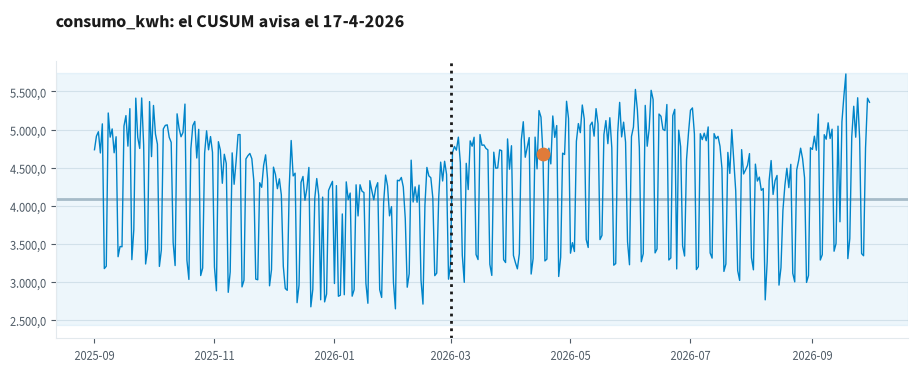

In [7]:
serie = b23[SERIE].loc["2025-09-01":]
media, rango_movil_medio, lci, lcs = limites_xmr(serie.loc[:"2026-02-28"])
sigma = rango_movil_medio / 1.128

# CUSUM por arriba y por abajo desde el 1 de marzo de 2026.
sube = baja = 0.0
alarma = None
for dia, valor in serie.loc["2026-03-01":].items():
    z = (valor - media) / sigma
    sube, baja = max(0.0, sube + z - 0.5), max(0.0, baja - z - 0.5)
    if alarma is None and max(sube, baja) > 5:
        alarma = dia
salto = serie.loc["2026-03-01":].mean() - serie.loc["2025-10-01":"2026-02-28"].mean()
print(f"{SERIE}: media de la fase I {n(media, 2)}, límites {n(lci, 2)} a {n(lcs, 2)}")
print(f"Cambio de marzo a septiembre frente a octubre-febrero: {n(salto, 2)}")
print("CUSUM:", f"avisa el {fecha(alarma)}" if alarma is not None else "no avisa")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axhspan(lci, lcs, color=estilo.AZUL, alpha=0.07)
ax.axhline(media, color=estilo.GRIS, linewidth=2)
ax.plot(serie.index, serie, color=estilo.AZUL, linewidth=1)
ax.axvline(pd.Timestamp("2026-03-01"), color=estilo.TEXTO, linestyle=":")
if alarma is not None:
    ax.scatter([alarma], [serie[alarma]], s=80, color=estilo.NARANJA, zorder=5)
estilo.formato_eje(ax, decimales=1)
ax.set_title(f"{SERIE}: {'el CUSUM avisa el ' + fecha(alarma) if alarma is not None else 'el CUSUM no avisa'}")
plt.show()

## 3. Separar: ¿pérdida real o medición a la baja?

El corazón del caso. Puede haber energía que **se pierde de verdad** (la base consume más) y energía que
**llega a las baterías pero se cuenta de menos** (no es pérdida: es un error de lectura). Pensad qué
dato distingue una cosa de la otra.

**3a. La pérdida real.** Pista: la Jornada 1 os dio una herramienta para ver pérdidas cuando casi no se
carga nada. Si la base consume más de noche, cuando las baterías apenas reciben energía, ¿puede ser un
problema de cómo cuentan las baterías?

In [8]:
# COMPLETAD: ¿cuántos kW más consume la base desde marzo de 2026, medidos donde las baterías no influyen?
# Comparad marzo-septiembre de 2026 con octubre de 2025-febrero de 2026 en la columna adecuada.
perdida_real_kw = 0.0

In [9]:
print(f"Pérdida real estimada: {n(perdida_real_kw, 2)} kW = {n(24 * perdida_real_kw)} kWh al día")

Pérdida real estimada: 0,00 kW = 0 kWh al día


**3b. La medición a la baja.** ¿Informan de menos las baterías viejas? No basta con mirar cuánta energía
dicen recibir: depende de cuántas baterías hay y de la estación. Comparad la **energía por batería** que
dicen recibir las BX-450 (primera generación) con la de las de segunda generación, que hacen el mismo
trabajo en la misma base: su cociente no debería moverse.

In [10]:
# COMPLETAD: energía al día por batería de cada generación (columnas entregada_g1_kwh, entregada_g2_kwh,
# baterias_g1 y baterias_g2). De partida, una versión ingenua que mezcla las dos generaciones.
por_bateria_g1 = b23["entregada_kwh"] / (b23["baterias_g1"] + b23["baterias_g2"])
por_bateria_g2 = b23["entregada_kwh"] / (b23["baterias_g1"] + b23["baterias_g2"])
cociente = por_bateria_g1 / por_bateria_g2

Cambio del cociente desde marzo de 2026: 0,00 %


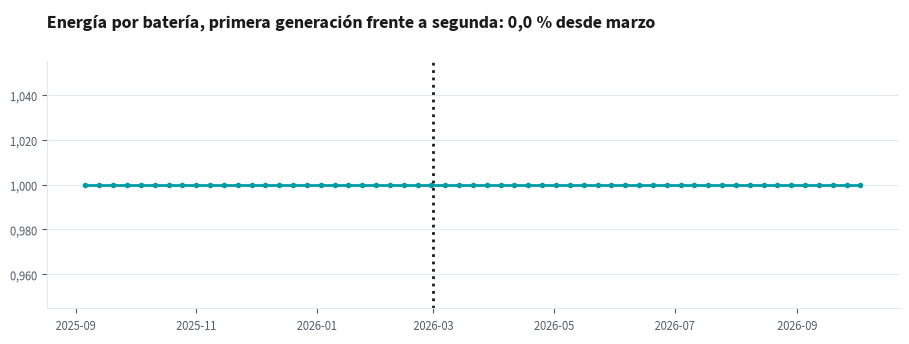

In [11]:
cambio_cociente = cociente.loc["2026-03-01":"2026-09-30"].mean() / cociente.loc["2025-10-01":"2026-02-28"].mean() - 1
print(f"Cambio del cociente desde marzo de 2026: {pct(cambio_cociente, 2)}")

semanal = cociente.loc["2025-09-01":].resample("W-SAT").mean()   # semanas de domingo a sábado
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(semanal.index, semanal, color=estilo.TURQUESA, marker="o", markersize=3)
ax.axvline(pd.Timestamp("2026-03-01"), color=estilo.TEXTO, linestyle=":")
estilo.formato_eje(ax, decimales=3)
ax.set_title(f"Energía por batería, primera generación frente a segunda: {pct(cambio_cociente, 1)} desde marzo")
plt.show()

**3c. De porcentaje a kW.** Si las BX-450 dicen haber recibido *E* kWh al día pero cuentan un *c* %
de menos, ¿cuánta energía han recibido de verdad, y cuánta es la diferencia? Pasadla a kW (entre 24).

In [12]:
# COMPLETAD: kW que llegan a las BX-450 pero se cuentan de menos (usad cambio_cociente y entregada_g1_kwh).
medicion_baja_kw = 0.0

In [13]:
total_kw = perdida_real_kw + medicion_baja_kw
print(f"Pérdida real:     {n(perdida_real_kw, 2)} kW ({n(24 * perdida_real_kw)} kWh al día)")
print(f"Medición a la baja: {n(medicion_baja_kw, 2)} kW ({n(24 * medicion_baja_kw)} kWh al día)")
if total_kw > 0:
    print(f"Total: {n(total_kw, 2)} kW; la pérdida real es el {pct(perdida_real_kw / total_kw, 0)}")
print(f"Energía perdida de verdad en un año: {n(perdida_real_kw * 24 * 365 / 1000, 1)} MWh")

Pérdida real:     0,00 kW (0 kWh al día)
Medición a la baja: 0,00 kW (0 kWh al día)
Energía perdida de verdad en un año: 0,0 MWh


## 4. Cuantificar con incertidumbre

¿Cuánto ha subido la energía no contabilizada? Comparad cada día de marzo a septiembre de 2026 con un
día de referencia, y dad un intervalo. Como los días seguidos se parecen entre sí, el intervalo se
calcula con errores HAC (Newey-West, 14 desfases), como en la Jornada 1. ¿Con qué días comparar para no
confundir la avería con la estación?

In [14]:
DESFASE_DIAS = 214   # ← cada día se compara con el de hace tantos días (214: los siete meses justo anteriores)

In [15]:
import statsmodels.api as sm

no_contabilizada = b23["no_contabilizada_kwh"]
ahora = no_contabilizada.loc["2026-03-01":"2026-09-30"]
antes = no_contabilizada.shift(DESFASE_DIAS).loc["2026-03-01":"2026-09-30"]   # el día de referencia de cada día
diferencias = (ahora - antes).dropna()
modelo = sm.OLS(diferencias.to_numpy(), np.ones(len(diferencias))).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
bajo, alto = modelo.conf_int()[0]
print(f"Subida de la energía no contabilizada: {n(diferencias.mean())} kWh al día "
      f"(IC del 95 %: {n(bajo)} a {n(alto)}), es decir, {n(diferencias.mean() / 24, 1)} kW")

Subida de la energía no contabilizada: 149 kWh al día (IC del 95 %: 138 a 160), es decir, 6,2 kW


## 5. Recomendar y vigilar

¿Qué opción recomendáis, con qué coste y con qué riesgo de equivocaros? ¿Y cómo vigilaréis que ha
funcionado: qué gráfico de control, sobre qué serie y qué esperáis ver? Elegid las series que
vigilaríais; la celda dibuja su gráfico de control en medias semanales, con los límites de septiembre
de 2025 a febrero de 2026.

In [16]:
vigilar = ["consumo_kwh"]   # ← columnas de diario.csv que vigilaríais, o "cociente" (el del paso 3b)

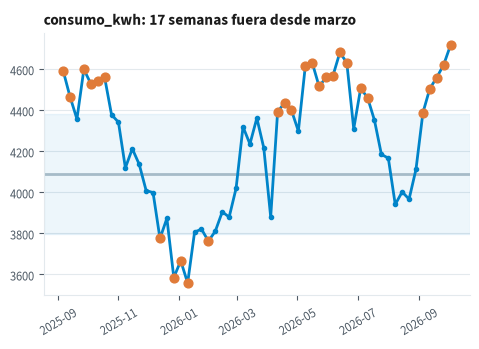

In [17]:
series = {columna: b23[columna] for columna in b23.columns if b23[columna].dtype.kind == "f"}
series["cociente"] = cociente
fig, ejes = plt.subplots(1, len(vigilar), figsize=(5.5 * len(vigilar), 3.4), squeeze=False)
for ax, nombre in zip(ejes[0], vigilar):
    semanal = series[nombre].loc["2025-09-01":].resample("W-SAT").mean()
    media, rango_movil_medio, lci, lcs = limites_xmr(semanal.loc[:"2026-02-28"])
    fuera = (semanal > lcs) | (semanal < lci)
    ax.axhspan(lci, lcs, color=estilo.AZUL, alpha=0.07)
    ax.axhline(media, color=estilo.GRIS, linewidth=2)
    ax.plot(semanal.index, semanal, color=estilo.AZUL, marker="o", markersize=3)
    ax.scatter(semanal.index[fuera], semanal[fuera], s=40, color=estilo.NARANJA, zorder=5)
    ax.set_title(f"{nombre}: {int(fuera.loc['2026-03-01':].sum())} semanas fuera desde marzo", fontsize=11, pad=6)
    ax.tick_params(axis="x", labelrotation=30)
plt.show()

## 6. La nota de decisión: una página, la conclusión primero

Copiad esta estructura en un documento y rellenadla. Tres minutos para contarla: **la primera frase
es la recomendación**.

> **Título que afirma la conclusión** (no «Análisis de la base B-23», sino lo que habéis encontrado,
> con una cifra).
>
> **Recomendación** (una frase): qué opción, y qué más hay que hacer.
>
> **Situación** (1–2 frases): qué se sabía. **Complicación** (1–2 frases): qué ha cambiado y por qué
> importa. **Resolución** (2–3 frases): qué explica el cambio, separado en sus partes.
>
> **Cifras, con su rango:** cuánto se pierde de verdad y cuánto es lectura, en kWh al día y al año, con
> un intervalo en lenguaje llano («entre … y … kWh al día, unos …»).
>
> **Coste y riesgo de equivocarse:** qué pasa si elegís la otra opción; qué pasa si os equivocáis.
>
> **Vigilancia:** qué gráfico de control, sobre qué serie, con qué límites, y qué esperáis ver si la
> medida funciona.
>
> **Datos:** qué auditasteis, qué excluisteis y por qué.
>
> Un único gráfico, con título que afirma y anotado (sin leyenda si se puede).

Así se valora (60 % de la evaluación del curso):

| Criterio | Peso | Qué se valora |
| --- | --- | --- |
| Calidad del dato | 15 % | Se auditó y se declararon las exclusiones |
| Método | 25 % | Técnica adecuada y validada contra una referencia |
| Incertidumbre | 15 % | Rango o intervalo, no solo un número |
| Recomendación y vigilancia | 25 % | Clara, con coste, riesgo de equivocarse y gráfico de control |
| Relato | 20 % | Conclusión primero, títulos que afirman, una página legible por un directivo |

Antes de presentar, preguntaos «¿cómo lo sabemos?» ante cada frase.

## Qué os lleváis

- Las cuatro jornadas en una decisión: **auditar** (cuadra, está en UTC, los días de cambio de hora no
  son huecos), **confirmar** con SPC en la serie adecuada, **separar** con el dato que distingue las
  causas, **cuantificar** con un rango frente a una referencia que respete la estación, y
  **recomendar** con un gráfico de control para el seguimiento.
- La media esconde lo que el mínimo nocturno enseña.
- La pregunta sugiere una respuesta (las baterías «viejas»); los datos pueden decir otra.
- Si el lector tiene que deducir la conclusión, la conclusión no está en la nota.